# ROC Curve and AUC


In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import auc, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
data = load_breast_cancer()
X = data.data
y = (data.target == 0).astype(int)  # 1 represents malignant cases

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
y_scores = model.predict_proba(X_test)[:, 1]

In [3]:
false_positive_rate, true_positive_rate, _ = roc_curve(y_test, y_scores)
roc_auc = auc(false_positive_rate, true_positive_rate)

print(f"Area Under the Curve (AUC): {roc_auc:.3f}")

Area Under the Curve (AUC): 0.996


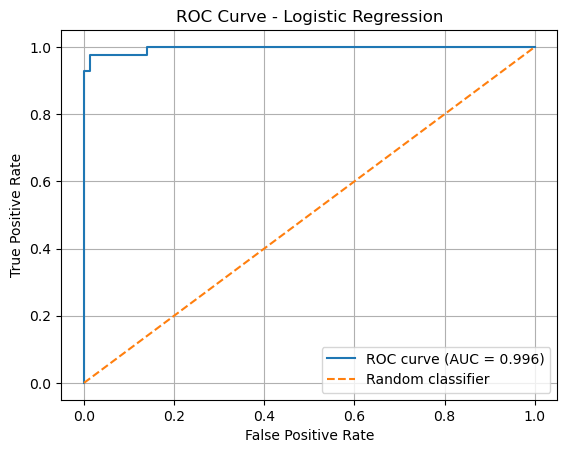

In [4]:
plt.plot(false_positive_rate, true_positive_rate, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()